# 06 Results
Prepares summary of the models results from notebook 05_models. No retraining is done.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

results = pd.read_csv("../outputs/results_all.csv")
print(len(results))

99


## AUROC table

Prepares a table to show the mean ± standard deviation of the AUROC score over the folds (antibiotic x model x split). The time split has only one fold, so std is not defined.

In [4]:
auroc_summary = (
    results
    .groupby(["antibiotic", "model", "split"])["AUROC"]
    .agg(["mean", "std"])
    .round(3)
)

auroc_summary

mean    std
antibiotic model        split                
CIP        boosting     lineage  0.908  0.040
                        random   0.967  0.010
                        time     0.955    NaN
           lineage_only lineage  0.500  0.000
                        random   0.931  0.010
                        time     0.922    NaN
           logistic     lineage  0.874  0.076
                        random   0.960  0.010
                        time     0.944    NaN
CXM        boosting     lineage  0.863  0.032
                        random   0.890  0.023
                        time     0.814    NaN
           lineage_only lineage  0.500  0.000
                        random   0.793  0.030
                        time     0.753    NaN
           logistic     lineage  0.842  0.025
                        random   0.887  0.022
                        time     0.814    NaN
GEN        boosting     lineage  0.966  0.011
                        random   0.965  0.020
                        time     0.991    NaN
           lineage_only lineage  0.500  0.000
                        random   0.794  0.026
                        time     0.760    NaN
           logistic     lineage  0.938  0.029
                        random   0.958  0.012
                        time     0.964    NaN

In [5]:
def format_cell(row):
    if pd.isna(row['std']):
        return f"{row['mean']:.3f}"
    return f"{row['mean']:.3f} ± {row['std']:.3f}"

auroc_table = auroc_summary.apply(format_cell, axis=1).unstack("split")
auroc_table = auroc_table[["random", "lineage", "time"]]
auroc_table

split                           random        lineage   time
antibiotic model                                            
CIP        boosting      0.967 ± 0.010  0.908 ± 0.040  0.955
           lineage_only  0.931 ± 0.010  0.500 ± 0.000  0.922
           logistic      0.960 ± 0.010  0.874 ± 0.076  0.944
CXM        boosting      0.890 ± 0.023  0.863 ± 0.032  0.814
           lineage_only  0.793 ± 0.030  0.500 ± 0.000  0.753
           logistic      0.887 ± 0.022  0.842 ± 0.025  0.814
GEN        boosting      0.965 ± 0.020  0.966 ± 0.011  0.991
           lineage_only  0.794 ± 0.026  0.500 ± 0.000  0.760
           logistic      0.958 ± 0.012  0.938 ± 0.029  0.964

### Interpretation

The gradient boosting model has the highest AUROC for all three antibiotics, in both the random and the lineage split. In the random split, the difference to logistic regression is small (under 0.01), so the two models perform about equally. In the lineage split, boosting is higher by about 0.02–0.03, which suggests that boosting performs better on families it has not seen.

The standard deviation (std) under the random split is small for every antibiotic (0.010–0.030), with 0.022–0.023 being the std for CXM.Under the lineage split, it increases clearly for CIP (from 0.010 to 0.040–0.076) and slightly for CXM (to 0.025–0.032). For GEN, it goes up for logistic regression (0.012 to 0.029) and down for boosting (0.020 to 0.011). This difference probably happens because, in the lineage split, each family stays in one fold, so folds end up being more different from each other. The largest family, where most strains are resistant to CIP and CXM but not GEN, is put in one fold.

Under the lineage split, the baseline scores exactly 0.500 ± 0.000 for every antibiotic. This confirms that no family information passes from training to test strains. Under the random split, the baseline comes close to the score of the gene model for CIP (0.931 against 0.960 and 0.967), but it is much lower for CXM (0.793 against 0.887 and 0.890) and GEN (0.794 against 0.958 and 0.965). So, for CIP, family information explains most of gene models' performance on a random split.

Under the time split, CIP scores are close to the random split (0.944–0.955), and the baseline alone reaches 0.922, so the same families seem to persist over time. CXM scores lowest here (0.814), possibly because its resistance changed between the periods. Since the time split has only one test set, these results should be read with caution.

## Balanced accuracy table

Prepares a table to show the mean ± standard deviation of the balanced accuracy score over the folds (antibiotic x model x split). The time split has only one fold, so std is not defined.

In [8]:
ba_summary = (
    results
    .groupby(["antibiotic", "model", "split"])["balanced_accuracy"]
    .agg(["mean", "std"])
    .round(3)
)

ba_table = ba_summary.apply(format_cell, axis=1).unstack("split")
ba_table = ba_table[["random", "lineage", "time"]]
ba_table

split                           random        lineage   time
antibiotic model                                            
CIP        boosting      0.901 ± 0.016  0.749 ± 0.114  0.898
           lineage_only  0.847 ± 0.022  0.500 ± 0.000  0.845
           logistic      0.911 ± 0.010  0.757 ± 0.120  0.895
CXM        boosting      0.842 ± 0.023  0.814 ± 0.028  0.732
           lineage_only  0.693 ± 0.028  0.500 ± 0.000  0.677
           logistic      0.826 ± 0.022  0.776 ± 0.041  0.741
GEN        boosting      0.922 ± 0.034  0.908 ± 0.005  0.969
           lineage_only  0.680 ± 0.032  0.500 ± 0.000  0.653
           logistic      0.893 ± 0.010  0.853 ± 0.044  0.900

### Interpretation

In both splits, the gradient boosting model performs better for CXM and GEN, while logistic scores slightly higher for CIP (by 0.010 for random and 0.008 for lineage). However, the lineage gap is tiny compared to its std (0.114 and 0.120) so the two models perform about the same under balanced accuracy. For GEN, the difference in performance is the highest (random: 0.922 vs. 0.893, lineage: 0.908 vs. 0.853).

The standard deviation under the random split lies between 0.010 and 0.034. Under the lineage split, it becomes very large for CIP (0.114–0.120), larger than in the AUROC table (0.040–0.076). This is probably because balanced accuracy depends on the 0.5 cut-off. The fold containing the largest family has many more resistant strains than the training data, so more strains fall on the wrong side of the cut-off, even when the model still ranks them reasonably well.

Overall, balanced accuracy shows the same picture as AUROC: CIP drops the most from the random to the lineage split (from about 0.90–0.91 to about 0.75), while GEN drops the least. The baseline again scores exactly 0.500 under the lineage split. Under the time split, CXM again has its lowest scores (0.732–0.741).

## Drop between random and lineage splits

Prepares a table for the drop in AUROC score between random and lineage splits.

- drop = random score − lineage score

A drop close to 0 means the model works just as well on new families, while larger drop shows that the model's resistance prediction relies on knowing the family. 

In [11]:
means = results.groupby(["antibiotic", "model", "split"])["AUROC"].mean().unstack("split")
means["drop"] = means["random"] - means["lineage"]
means[["random", "lineage", "drop"]].round(3)

split                    random  lineage   drop
antibiotic model                               
CIP        boosting       0.967    0.908  0.060
           lineage_only   0.931    0.500  0.431
           logistic       0.960    0.874  0.086
CXM        boosting       0.890    0.863  0.026
           lineage_only   0.793    0.500  0.293
           logistic       0.887    0.842  0.045
GEN        boosting       0.965    0.966 -0.002
           lineage_only   0.794    0.500  0.294
           logistic       0.958    0.938  0.020

### Interpretation

For both models, the drop values follow the order: GEN < CXM < CIP.
<br>
Boosting drop:
-0.002 < 0.026 < 0.060
<br>
Logistic drop:
0.020 < 0.045 < 0.086

This is the order the hypothesis predicts. Logistic regression drops more than boosting for every antibiotic, which aligns with boosting performing better on new families. For GEN, the boosting drop is negative, so it scores slightly higher on new families and shows no drop at all.

Compared with the standard deviation under the lineage split, the CIP drop (0.060–0.086) is larger than the variation between folds (0.040–0.076), although for logistic regression only just. The CXM drop (0.026–0.045) is about the same size as its variation (0.025–0.032), so it is less certain, and the GEN drop is within the variation (0.011–0.029).

The baseline's drop is its random-split score minus 0.5, so it shows how much family alone can predict. It is largest for CIP (0.431) and almost the same for CXM and GEN (0.293 and 0.294). So family is most informative for CIP, which is also the antibiotic whose gene models drop most when families are held out.

Overall, the results support the hypothesis, but they are based on five folds without a statistical test.

## AUROC chart
A chart showing how each antibiotic's AUROC changes from the random to the lineage to the time split.

Notation:
    
    - dots: mean values
    - lines: ± std
    - dashed line: chance

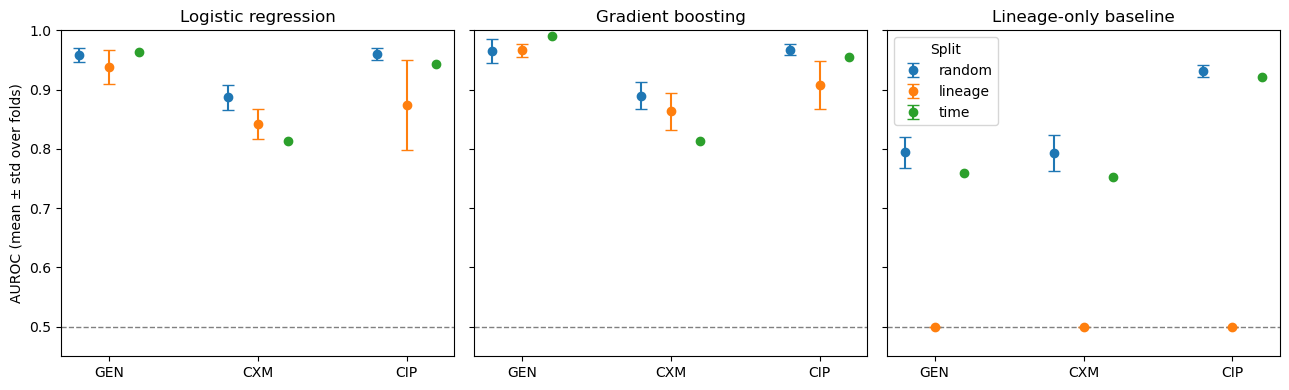

In [14]:
antibiotic_order = ["GEN", "CXM", "CIP"]
split_order = ["random", "lineage", "time"]
model_order = ["logistic", "boosting", "lineage_only"]
model_titles = {
    "logistic": "Logistic regression",
    "boosting": "Gradient boosting",
    "lineage_only": "Lineage-only baseline"
}
offsets = {"random": -0.2, "lineage": 0.0, "time": 0.2}

stats = results.groupby(["model", "antibiotic", "split"])["AUROC"].agg(["mean", "std"])

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
x = np.arange(len(antibiotic_order))

for ax, model in zip(axes, model_order):
    for split in split_order:
        means = [stats.loc[(model, ab, split), "mean"] for ab in antibiotic_order]
        stds = [stats.loc[(model, ab, split), "std"] for ab in antibiotic_order]
        ax.errorbar(x + offsets[split], means, yerr=stds, fmt="o", capsize=4, label=split)
    ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(antibiotic_order)
    ax.set_title(model_titles[model])

axes[0].set_ylabel("AUROC (mean ± std over folds)")
axes[0].set_ylim(0.45, 1.0)
axes[-1].legend(title="Split")
plt.tight_layout()
plt.savefig("../figures/auroc_by_split.png", dpi=200, bbox_inches="tight")
plt.show()

### Interpretation

The chart shows the same order as the drop table: in both gene-model panels, GEN barely changes from the random to the lineage split, CXM drops a bit, and CIP drops the most. The error bars make the difference visible: for GEN and CXM, the random and lineage error bars overlap, while for CIP they overlap only slightly or not at all, so the CIP drop is the clearest. In the baseline panel, the lineage dots are exactly on the chance line, and CIP's random dot is almost as high as the gene models, which shows how much of CIP's performance comes from family alone.

## Summary

- The drop from the random to the lineage split follows GEN < CXM < CIP for both models and both metrics.
- CIP drops the most: AUROC by 0.06–0.09, balanced accuracy by about 0.15.
- The lineage-only baseline scores exactly 0.5 under the lineage split; under the random split it reaches 0.93 for CIP, but only about 0.79 for GEN and CXM.
- Boosting scores slightly higher than logistic regression, especially under the lineage split.
- Under the time split, CXM scores lowest; this cannot be confirmed with only one test set.